# Project work 4, Mattia Franchi

## Useful Links
- GitHub: https://github.com/m4tti4fr4nchi/ind320-m4tti4fr4nchi
- Streamlit: https://ind320-m4tti4fr4nchi-ybf3fy4znakvdenhn4kked.streamlit.app/
- Video: (link added after recording)

## Use of AI
(to be written)

## Log
(to be written)

## 1. Exchange rates from Norges Bank
### Make a function for downloading Euro and USD currency exchange rates from the Norwegian Bank (NB) currency API and show that it works.

In [1]:
import io
import requests
import pandas as pd
import matplotlib.pyplot as plt

# Norges Bank's open SDMX API: B = business-day frequency, SP = spot rate, quoted in NOK per unit of currency
NB_URL = "https://data.norges-bank.no/api/data/EXR/B.{currencies}.NOK.SP"


def download_exchange_rates(start_date, end_date, currencies=("EUR", "USD")):
    """Daily exchange rates (NOK per unit of currency) from Norges Bank between two dates (YYYY-MM-DD).

    Several currencies are requested in one call by joining them with "+".
    Returns one column per currency and one row per business day.
    """
    params = {"format": "csv", "startPeriod": start_date, "endPeriod": end_date, "locale": "en"}
    response = requests.get(NB_URL.format(currencies="+".join(currencies)), params=params, timeout=60)
    response.raise_for_status()

    raw = pd.read_csv(io.StringIO(response.text), sep=";")   # the CSV uses semicolons
    # Long format (one row per currency and day) -> wide format (one column per currency)
    rates = (raw.pivot(index="TIME_PERIOD", columns="BASE_CUR", values="OBS_VALUE")
             .rename_axis(index="date", columns=None))
    rates.index = pd.to_datetime(rates.index)
    return rates[list(currencies)]

(2768, 2)


,count,mean,std,min,25%,50%,75%,max
EUR,2768.0,10.25,0.98,8.33,9.49,10.03,11.29,12.32
USD,2768.0,9.18,1.04,7.36,8.36,8.80,10.15,11.48


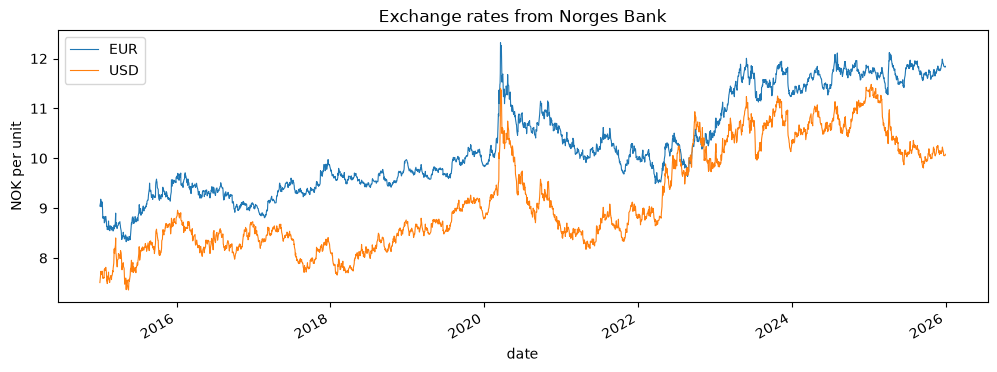

In [2]:
# Test: the last ten years, the same period as the reservoir and weather analyses below
rates = download_exchange_rates("2015-01-01", "2025-12-31")
print(rates.shape)
display(rates.describe().round(2).T)

fig, ax = plt.subplots(figsize=(12, 4))
rates.plot(ax=ax, linewidth=0.8)
ax.set_ylabel("NOK per unit")
ax.set_title("Exchange rates from Norges Bank")
plt.show()

In [3]:
# Test 2: Easter 2024 - only business days are published (no values on 28 March - 1 April)
download_exchange_rates("2024-03-25", "2024-04-03")

,EUR,USD
date,,
2024-03-25,11.6050,10.7107
2024-03-26,11.6260,10.7103
2024-03-27,11.6825,10.8011
2024-04-02,11.7080,10.8922
2024-04-03,11.6580,10.8115


The function returns one value per business day. The Norwegian krone weakened against both currencies over the period, especially in 2020 (Covid-19) and 2022–2023. Weekends and public holidays (e.g. Easter 2024) have no values, so the series must be forward-filled or averaged before it is combined with daily or weekly data.

## 2. Time zones of the data sources
### Investigate possible timezone differences between Magasinstatistikk, ENTSO-E, OpenMeteo and NB and report your findings, plus solutions if needed.

In [4]:
import tomllib
from pymongo import MongoClient

# --- Magasinstatistikk: weekly values, labelled with a date without time or time zone ---
nve = pd.DataFrame(requests.get("https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData",
                                timeout=60).json())
nve_dates = pd.to_datetime(nve["dato_Id"])
print("Magasinstatistikk:", nve["dato_Id"].iloc[0], "| time zone:", nve_dates.dt.tz,
      "| weekdays:", nve_dates.dt.day_name().unique().tolist())

# --- ENTSO-E: the API answers in UTC ("...Z"); the notebook of part 2 stored UTC timestamps in MongoDB ---
with open("../.streamlit/secrets.toml", "rb") as f:
    secrets = tomllib.load(f)
flows = MongoClient(secrets["mongo"]["uri"])["ind320"]["cross_border_flows"]
first = flows.find_one({}, {"_id": 0, "timestamp": 1})
print("ENTSO-E (MongoDB):", first["timestamp"], "| stored as naive UTC")

# --- Norges Bank: one value per business day, fixed at 14:15 CET, no weekends or holidays ---
print("Norges Bank:", rates.index[0].date(), "| weekdays:", sorted(rates.index.day_name().unique()))

Magasinstatistikk: 2020-11-15 | time zone: None | weekdays: ['Sunday']
ENTSO-E (MongoDB): 2024-10-14 17:00:00 | stored as naive UTC
Norges Bank: 2015-01-02 | weekdays: ['Friday', 'Monday', 'Thursday', 'Tuesday', 'Wednesday']


In [5]:
# --- open-meteo: compare the same day downloaded with timezone="UTC" and timezone="Europe/Oslo" ---
def temperature(timezone, start_date, end_date):
    """Hourly ERA5 temperature in Trondheim with the chosen time zone, plus the offset reported by the API."""
    params = dict(latitude=63.43, longitude=10.39, start_date=start_date, end_date=end_date,
                  hourly="temperature_2m", models="era5", timezone=timezone)
    answer = requests.get("https://archive-api.open-meteo.com/v1/archive", params=params, timeout=60).json()
    series = pd.Series(answer["hourly"]["temperature_2m"], index=pd.to_datetime(answer["hourly"]["time"]))
    return series, answer["utc_offset_seconds"] / 3600

for start, end in [("2024-01-10", "2024-01-11"), ("2024-07-10", "2024-07-11")]:   # winter time and summer time
    utc, _ = temperature("UTC", start, end)
    oslo, offset = temperature("Europe/Oslo", start, end)
    # Shift (in hours) that makes the two series identical
    shift = next(k for k in range(4) if (oslo.values[k:] == utc.values[:len(utc) - k]).all())
    print(f"{start}: reported offset {offset:+.0f} h, Oslo series = UTC series shifted by {shift} h")

# Days with the change to and from summer time: number of hours per local day
oslo_spring, _ = temperature("Europe/Oslo", "2024-03-30", "2024-04-01")
oslo_autumn, _ = temperature("Europe/Oslo", "2024-10-26", "2024-10-28")
print("Hours per day (spring):", oslo_spring.groupby(oslo_spring.index.date).size().tolist())
print("Hours per day (autumn):", oslo_autumn.groupby(oslo_autumn.index.date).size().tolist())

2024-01-10: reported offset +1 h, Oslo series = UTC series shifted by 1 h
2024-07-10: reported offset +1 h, Oslo series = UTC series shifted by 1 h
Hours per day (spring): [24, 24, 24]
Hours per day (autumn): [24, 24, 24]


| Source | Time resolution | Time stamps | Time zone |
|---|---|---|---|
| Magasinstatistikk | Weekly | Date of the Sunday that ends the ISO week (`dato_Id`), plus ISO year and week | None: Norwegian calendar weeks |
| ENTSO-E | 15 min / hourly | Start time of each interval | UTC in the API; stored as UTC in MongoDB (part 2) |
| open-meteo | Hourly | Start of each hour | Chosen with `timezone`. `UTC` is exact; `Europe/Oslo` applies **one fixed offset** (+1 h) to the whole request, so summer values are one hour off from Norwegian summer time and the days with a clock change still have 24 hours |
| Norges Bank | Business days | Date only | None: fixing at 14:15 CET, no weekends or holidays |

**Solution:** I keep all hourly data in UTC (as in parts 2 and 3), so there are no missing or duplicated hours at the clock changes. When the sources are combined, everything is aggregated to the weekly resolution of Magasinstatistikk: hourly UTC values are averaged per week ending on Sunday (`W-SUN`), and the exchange rates are forward-filled over weekends and holidays before the weekly average. At weekly resolution, the one- or two-hour difference between UTC and Norwegian time has no practical effect.

## 3. Weather data for more locations
### Teacher feedback on part 3: more of the sampled locations should be included and grouped efficiently in the Open-Meteo requests.

In part 3, the weather of an area was the average of only 10 of its 1000 random locations, because of open-meteo's limits: one year for one location counts as about 26 API calls, and the free API allows 10 000 calls per day. Downloading all 8000 points for one year would need about 208 000 calls.

The solution is to group the points before downloading. ERA5 has a resolution of about 30 km, and the weather changes slowly in space, so points close to each other have almost the same weather. I group all 8000 points on a 1-degree grid: each group is downloaded once, at the mean position of its points, and the weather of an area is the mean of its groups, **weighted by the number of the area's points in each group**. In this way all 1000 points of each area contribute, with 16–83 downloaded locations per area instead of 10. The price areas and the precipitation areas cover the same country, so they share the groups and nothing is downloaded twice.

8000 points -> 130 location groups


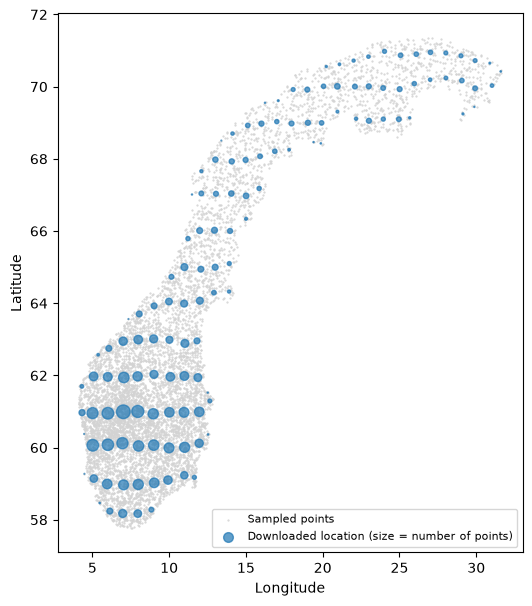

area,NO1,NO2,NO3,NO4,NO5,VASS1,VASS2,VASS3
groups per area,22,19,30,71,16,35,23,83


In [6]:
import numpy as np

# All 8000 locations sampled in part 3 (1000 per price area and per precipitation area)
mongo_db = MongoClient(secrets["mongo"]["uri"])["ind320"]
points = pd.DataFrame(list(mongo_db["sample_points"].find({}, {"_id": 0})))

# Group the points on a 1-degree grid. Points close to each other have almost the same ERA5 weather, so each
# group is downloaded once, at the mean position of its points. The grid is shared by the price areas and the
# precipitation areas, which cover the same country, so a group can serve several areas.
GRID_DEGREES = 1.0
points["group_lat"] = (points["latitude"] / GRID_DEGREES).round().astype(int)
points["group_lon"] = (points["longitude"] / GRID_DEGREES).round().astype(int)
groups = (points.groupby(["group_lat", "group_lon"])
          .agg(latitude=("latitude", "mean"), longitude=("longitude", "mean"), n_points=("point_id", "size"))
          .reset_index())
groups["group_id"] = range(len(groups))
groups[["latitude", "longitude"]] = groups[["latitude", "longitude"]].round(4)

# Weight of each group in each area = number of that area's 1000 points that fall in the group
weights = (points.merge(groups[["group_lat", "group_lon", "group_id"]], on=["group_lat", "group_lon"])
           .groupby(["area", "group_id"]).size().rename("weight").reset_index())

print(f"{len(points)} points -> {len(groups)} location groups")

# Map of the groups: the size of each dot is the number of sampled points it represents
fig, ax = plt.subplots(figsize=(6, 7))
ax.scatter(points["longitude"], points["latitude"], s=0.3, color="lightgrey", label="Sampled points")
ax.scatter(groups["longitude"], groups["latitude"], s=groups["n_points"] / 3, color="tab:blue", alpha=0.7,
           label="Downloaded location (size = number of points)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend(loc="lower right", fontsize=8)
plt.show()
weights.groupby("area")["group_id"].nunique().rename("groups per area").to_frame().T

In [7]:
import time
from pathlib import Path

ARCHIVE_URL = "https://archive-api.open-meteo.com/v1/archive"
WEATHER_VARIABLES = ["temperature_2m", "precipitation", "rain", "snowfall", "relative_humidity_2m",
                     "cloud_cover", "wind_speed_10m", "wind_gusts_10m"]   # at most 10 -> no extra weight
RAW_DIR = Path("../No_sync/weather_raw")    # local cache of the raw downloads (No_sync/ is not on GitHub)


def download_weather_groups(groups, start_date, end_date, raw_dir=RAW_DIR, chunk_size=20, pause=380):
    """Hourly ERA5 data (UTC) for all location groups between two dates, saved chunk by chunk in `raw_dir`.

    open-meteo's free API allows 600 calls per minute, 5000 per hour and 10 000 per day, and one year for one
    location counts as about 26 calls. So `chunk_size` locations are sent in one request (20 x 26 = 520 calls),
    with `pause` seconds between requests (about 9 requests = 4700 calls per hour). Chunks already on disk are
    skipped, so after the daily limit the function can simply be run again later and continues where it stopped. Returns True when all chunks are done.
    """
    raw_dir.mkdir(parents=True, exist_ok=True)
    for start in range(0, len(groups), chunk_size):
        chunk = groups.iloc[start:start + chunk_size]
        path = raw_dir / f"{start_date}_{start:03d}.parquet"
        if path.exists():
            continue
        params = {
            "latitude": ",".join(chunk["latitude"].astype(str)),    # several locations in one request
            "longitude": ",".join(chunk["longitude"].astype(str)),
            "start_date": start_date, "end_date": end_date,
            "hourly": ",".join(WEATHER_VARIABLES), "models": "era5", "timezone": "UTC",
        }
        for attempt in range(5):   # the internet connection may drop for a moment: wait and try again
            try:
                response = requests.get(ARCHIVE_URL, params=params, timeout=300)
                break
            except (requests.ConnectionError, requests.Timeout) as error:
                print(f"Connection problem ({type(error).__name__}), new attempt in 60 s...")
                time.sleep(60)
        else:
            print("No connection to open-meteo. Run the cell again later.")
            return False
        if response.status_code == 429:   # limit reached: stop here, the next run continues from this chunk
            print(f"{start_date}: open-meteo limit reached at location {start}. Run the cell again later.")
            return False
        response.raise_for_status()
        blocks = response.json()
        blocks = blocks if isinstance(blocks, list) else [blocks]   # one location -> one object, several -> a list
        frames = [pd.DataFrame(block["hourly"]).assign(group_id=group_id)
                  for group_id, block in zip(chunk["group_id"], blocks)]
        pd.concat(frames).to_parquet(path)
        print(f"{start_date}: locations {start}-{start + len(chunk) - 1} of {len(groups)} saved "
              f"({pd.Timestamp.now():%H:%M})")
        time.sleep(pause)   # stay below the limits per minute and per hour
    return True


def area_weather(raw_dir, weights):
    """Hourly weather of every area: weighted mean over its location groups (weight = number of points).

    The raw files are processed one at a time (weighted sums per area and hour), so the memory use stays small.
    """
    sums = []
    for path in sorted(raw_dir.glob("*.parquet")):
        merged = pd.read_parquet(path).merge(weights, on="group_id")   # one row per hour, group and area
        weighted = merged[WEATHER_VARIABLES].mul(merged["weight"], axis=0)
        weighted[["area", "time", "weight"]] = merged[["area", "time", "weight"]]
        sums.append(weighted.groupby(["area", "time"]).sum())
    total = pd.concat(sums).groupby(level=["area", "time"]).sum()   # add up the chunks of the same hour
    means = total[WEATHER_VARIABLES].div(total["weight"], axis=0).round(2).reset_index()
    means["time"] = pd.to_datetime(means["time"])
    return means

In [8]:
# Small test before the long download: 3 location groups and 2 days, without pauses (only a few API calls)
test_dir = Path("../No_sync/weather_test")
for old in test_dir.glob("*.parquet"):
    old.unlink()   # start the test from scratch
download_weather_groups(groups.head(3), "2024-07-01", "2024-07-02", raw_dir=test_dir, chunk_size=2, pause=0)
test = area_weather(test_dir, weights[weights["group_id"] < 3])
print(sorted(test_dir.glob("*.parquet")))
test.groupby("area").size()

2024-07-01: locations 0-1 of 3 saved (10:36)
2024-07-01: locations 2-2 of 3 saved (10:36)
[WindowsPath('../No_sync/weather_test/2024-07-01_000.parquet'), WindowsPath('../No_sync/weather_test/2024-07-01_002.parquet')]


area
NO2      48
VASS1    48
dtype: int64

The test downloads two chunks (2 + 1 locations) and computes the weighted hourly mean for the areas that the three groups belong to. The full download below covers 2021–2025, the period used for the correlations and the forecasts.

In [9]:
# The long download: 130 location groups x 5 years, about 17 000 API calls in total.
# With the daily limit of 10 000 calls it takes two days: when the limit is reached, run this cell again later.
YEARS = range(2021, 2026)
for year in YEARS:
    if not download_weather_groups(groups, f"{year}-01-01", f"{year}-12-31"):
        break
print(len(list(RAW_DIR.glob("*.parquet"))), "of", 7 * len(YEARS), "chunks downloaded")

35 of 35 chunks downloaded


In [10]:
# Hourly weather of every area: weighted mean of its location groups, computed from the raw downloads
weather_areas = area_weather(RAW_DIR, weights)
print(weather_areas.shape)
weather_areas.groupby("area")["time"].agg(["min", "max", "count"])

(350592, 10)


,min,max,count
area,,,
NO1,2021-01-01,2025-12-31 23:00:00,43824
NO2,2021-01-01,2025-12-31 23:00:00,43824
NO3,2021-01-01,2025-12-31 23:00:00,43824
NO4,2021-01-01,2025-12-31 23:00:00,43824
NO5,2021-01-01,2025-12-31 23:00:00,43824
VASS1,2021-01-01,2025-12-31 23:00:00,43824
VASS2,2021-01-01,2025-12-31 23:00:00,43824
VASS3,2021-01-01,2025-12-31 23:00:00,43824


In [11]:
# Store the hourly weather of every area in MongoDB, where the Streamlit app reads it
weather_collection = mongo_db["weather_hourly"]
weather_collection.delete_many({})   # replace everything, so re-running does not duplicate hours
records = weather_areas.to_dict("records")
for start in range(0, len(records), 20_000):   # insert in batches to keep each request small
    weather_collection.insert_many(records[start:start + 20_000])
weather_collection.create_index([("area", 1), ("time", 1)])   # the app always filters on area and time
print(weather_collection.count_documents({}), "hourly area values stored in MongoDB.")

350592 hourly area values stored in MongoDB.


## 4. Forecasting the reservoir filling with River
### Make a function for forecasting the filling of a single region with River (SARIMAX/SNARIMAX). Model parameters, length of the training history, forecast horizon and data sources are inputs. Test several settings and choose the best one as default for the Streamlit app.

**Choices.** The forecast uses **weekly resolution**, because Magasinstatistikk is weekly: the hourly weather (UTC) is aggregated to weeks ending on Sunday (totals for precipitation, rain and snowfall, means for the rest), and the exchange rates are forward-filled over weekends and holidays and averaged per week (see section 2). The model is River's **SNARIMAX**, the streaming version of SARIMAX: it learns one week at a time, so it can be updated when a new week is published. The seasonal part uses a period of 52 weeks, since the filling follows the yearly cycle of snow melt in spring and emptying in winter.

The filling is known from 1995, the weather in MongoDB from 2021. With exogenous variables the training therefore starts in 2021, and the values of the exogenous variables must be known for the forecast weeks. In the tests below the observed weather is used, which is the same as assuming a perfect weather forecast.

In [12]:
from river import time_series, preprocessing, linear_model, optim

NVE_URL = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"
SUM_VARIABLES = ["precipitation", "rain", "snowfall"]   # weekly totals; the other weather variables are weekly means


def weekly_dataset(area, mongo_db):
    """Weekly table for one area, with weeks ending on Sunday (as in Magasinstatistikk).

    - filling_rate and filling_twh from the NVE API (Magasinstatistikk), from 1995;
    - weekly weather of the area from MongoDB (hourly UTC values -> weekly totals or means), from 2021;
    - EUR and USD from Norges Bank, forward-filled over weekends and holidays, then averaged per week.
    """
    nve = pd.DataFrame(requests.get(NVE_URL, timeout=60).json())
    nve["area"] = [f"NO{n}" if kind == "EL" else f"VASS{n}" if kind == "VASS" else "Norway"
                   for kind, n in zip(nve["omrType"], nve["omrnr"])]
    filling = (nve[nve["area"] == area]
               .assign(date=lambda df: pd.to_datetime(df["dato_Id"]))
               .set_index("date").sort_index()
               .rename(columns={"fyllingsgrad": "filling_rate", "fylling_TWh": "filling_twh"})
               [["filling_rate", "filling_twh"]])

    hourly = pd.DataFrame(list(mongo_db["weather_hourly"].find({"area": area}, {"_id": 0, "area": 0})))
    hourly = hourly.set_index("time").sort_index()
    rules = {column: "sum" if column in SUM_VARIABLES else "mean" for column in hourly.columns}
    weeks = hourly.resample("W-SUN")
    weather = weeks.agg(rules)[weeks.size() == 168]   # keep only complete weeks (7 x 24 hours)

    rates = download_exchange_rates(f"{filling.index.min():%Y-%m-%d}", f"{filling.index.max():%Y-%m-%d}")
    rates = rates.asfreq("D").ffill().resample("W-SUN").mean()

    return filling.join(weather).join(rates)

In [13]:
# Example: the weekly table of NO5 (western Norway, the area with the largest reservoirs)
data_no5 = weekly_dataset("NO5", mongo_db)
print(data_no5.shape)
display(data_no5.loc["2024-12-15":"2025-01-05"].round(2).T)

(1663, 12)


date,2024-12-15,2024-12-22,2024-12-29,2025-01-05
filling_rate,0.78,0.77,0.77,0.73
filling_twh,13.65,13.43,13.32,12.68
temperature_2m,-1.98,-0.31,1.42,-7.90
precipitation,57.93,84.84,66.87,29.03
rain,33.77,49.40,45.61,2.65
snowfall,16.89,24.77,14.88,18.59
relative_humidity_2m,83.24,86.24,90.27,81.41
cloud_cover,73.93,81.92,91.88,80.12
wind_speed_10m,9.38,15.26,12.38,10.35
wind_gusts_10m,29.03,44.44,38.06,29.86


In [14]:
def forecast_filling(data, train_end, horizon=12, history_weeks=1000, exog=(), order=(1, 1, 1),
                     seasonal_order=(1, 1, 0, 52), target="filling_rate", learning_rate=0.01):
    """Forecast the weekly reservoir filling of one area with River's SNARIMAX.

    data            weekly table from weekly_dataset()
    train_end       last week used for training (the forecast starts the week after)
    horizon         number of weeks to forecast
    history_weeks   length of the training history (counted back from train_end)
    exog            exogenous columns of `data` (weather variables, EUR, USD); their values must be known
                    for every forecast week, so with exogenous variables the forecast cannot go past the data
    order, seasonal_order   (p, d, q) and (P, D, Q, m) of the SNARIMAX model, as in SARIMAX of statsmodels
    Returns a DataFrame with the forecast and, where available, the actual values.
    """
    exog = list(exog)
    available = data[[target] + exog].dropna()            # weeks where the target and all inputs exist
    train = available[available.index <= train_end].iloc[-history_weeks:]
    dates = pd.date_range(train.index[-1], periods=horizon + 1, freq="W-SUN")[1:]
    if exog:
        future = data[exog].reindex(dates)
        if future.isna().any().any():
            raise ValueError("The exogenous variables are not known for all the forecast weeks.")
        xs = future.to_dict("records")
    else:
        xs = [{}] * horizon

    p, d, q = order
    sp, sd, sq, m = seasonal_order
    # The regressor learns the (differenced) filling from its own lags, the past errors and the exogenous inputs
    regressor = (preprocessing.StandardScaler() |
                 linear_model.LinearRegression(optimizer=optim.SGD(learning_rate), intercept_lr=0.1))
    model = time_series.SNARIMAX(p=p, d=d, q=q, m=m, sp=sp, sd=sd, sq=sq, regressor=regressor)
    for _, row in train.iterrows():                      # streaming: the model learns one week at a time
        model.learn_one(row[target], {column: row[column] for column in exog})

    result = pd.DataFrame({"forecast": model.forecast(horizon=horizon, xs=xs)}, index=dates)
    result["actual"] = data[target].reindex(dates)
    return result

Mean absolute error: 5.6 percentage points


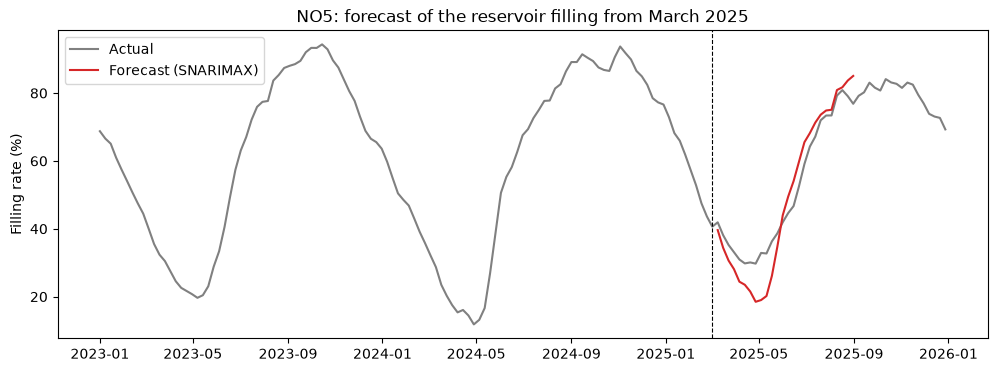

In [15]:
# Example: forecast of the 26 weeks after 2 March 2025 (spring and summer), with precipitation as exogenous input
example = forecast_filling(data_no5, "2025-03-02", horizon=26, exog=["precipitation"])
print(f"Mean absolute error: {(example['forecast'] - example['actual']).abs().mean() * 100:.1f} percentage points")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(data_no5.loc["2023":"2025", "filling_rate"] * 100, color="grey", label="Actual")
ax.plot(example["forecast"] * 100, color="tab:red", label="Forecast (SNARIMAX)")
ax.axvline(pd.Timestamp("2025-03-02"), color="black", linestyle="--", linewidth=0.8)
ax.set_ylabel("Filling rate (%)")
ax.set_title("NO5: forecast of the reservoir filling from March 2025")
ax.legend()
plt.show()

In [16]:
def backtest(data, settings, origins, horizon=12):
    """Mean absolute error (percentage points) of forecast_filling over several forecast origins."""
    errors = []
    for origin in origins:
        result = forecast_filling(data, origin, horizon=horizon, **settings)
        errors.append((result["forecast"] - result["actual"]).abs().mean())
    return 100 * sum(errors) / len(errors)


# 14 forecast origins, every 6 weeks from March 2024 to September 2025, each followed by 12 weeks to forecast
origins = pd.date_range("2024-03-03", "2025-09-28", freq="6W-SUN")
SETTINGS = {
    "ARIMA(1,1,1), no season": dict(seasonal_order=(0, 0, 0, 52)),
    "SNARIMAX, 4 years": dict(history_weeks=208),
    "SNARIMAX, 10 years": dict(history_weeks=520),
    "SNARIMAX, 19 years": dict(history_weeks=1000),
    "SNARIMAX + precipitation": dict(exog=["precipitation"]),
    "SNARIMAX + temperature": dict(exog=["temperature_2m"]),
    "SNARIMAX + precipitation, temperature, snowfall": dict(exog=["precipitation", "temperature_2m", "snowfall"]),
    "SNARIMAX + precipitation, EUR": dict(exog=["precipitation", "EUR"]),
}
datasets = {area: weekly_dataset(area, mongo_db) for area in ["NO1", "NO2", "NO3", "NO4", "NO5"]}
scores = pd.DataFrame({area: {name: backtest(data, settings, origins) for name, settings in SETTINGS.items()}
                       for area, data in datasets.items()})
# Reference: "nothing changes", i.e. the last known value repeated for the 12 weeks
scores.loc["Naive (last value)"] = {
    area: 100 * sum((data.loc[data.index > o, "filling_rate"].iloc[:12] - data.loc[o, "filling_rate"]).abs().mean()
                    for o in origins) / len(origins)
    for area, data in datasets.items()}
scores["mean"] = scores.mean(axis=1)
scores.round(1)

,NO1,NO2,NO3,NO4,NO5,mean
"ARIMA(1,1,1), no season",15.9,8.5,12.1,7.9,12.8,11.4
"SNARIMAX, 4 years",11.8,8.4,9.4,5.3,8.5,8.7
"SNARIMAX, 10 years",11.8,8.1,9.5,5.3,8.1,8.6
"SNARIMAX, 19 years",11.8,8.1,9.5,5.3,8.1,8.6
SNARIMAX + precipitation,12.0,7.1,9.0,5.5,7.9,8.3
SNARIMAX + temperature,11.9,8.8,9.9,6.2,9.0,9.2
"SNARIMAX + precipitation, temperature, snowfall",12.2,7.4,9.5,6.1,8.4,8.7
"SNARIMAX + precipitation, EUR",12.5,7.2,9.0,5.5,8.1,8.5
Naive (last value),15.7,8.0,12.2,9.3,15.3,12.1


**Findings.** The seasonal part is the most important: without it (plain ARIMA) the error is about as large as with the naive forecast, because the model cannot know that the filling turns in spring and in autumn. With the 52-week season the mean error over 12 weeks drops from 12.1 to 8.6 percentage points. A longer history helps only a little (4 years 8.7, 10 and 19 years 8.6), since SNARIMAX keeps learning and adapts to the recent years. Precipitation is the only useful exogenous variable (8.3 on average; best in NO2, NO3 and NO5, the western and central areas with much rain), while temperature, snowfall and the euro rate do not improve the forecast with only four years of training data. NO1 is the hardest area (about 12 points), probably because its smaller reservoirs depend more on how the producers run them.

**Default for the Streamlit app:** SNARIMAX(1,1,1)(1,1,0,52), weekly resolution, training from 2021 with precipitation as exogenous variable, horizon 12 weeks.

## 5. GeoJSON of the areas for the map
The interactive map of the Streamlit app needs the outlines of the areas. The shapefiles from NVE are large and kept outside Git (`No_sync/`), so they are converted once here to a small GeoJSON file in `data/`, which the app reads. The outlines are simplified with a tolerance of 500 m, which is invisible at the zoom level of a map of Norway, and converted from UTM (EPSG:25833) to longitude/latitude (EPSG:4326), the coordinates used by web maps.

..\data\areas.geojson: 0.13 MB


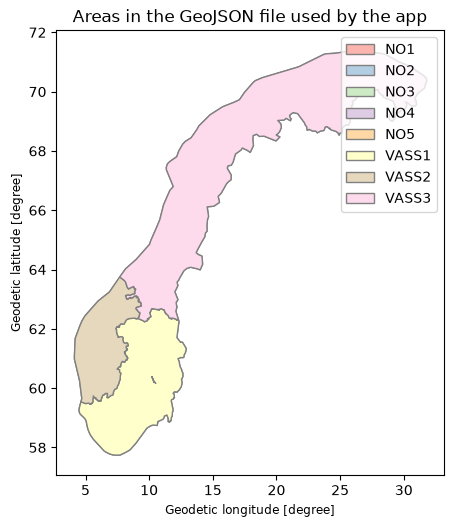

In [17]:
import geopandas as gpd

# Same polygons as in part 3: price areas from Budområder, precipitation areas from the NVE regions
SHAPE_DIR = "../No_sync"
price_areas = gpd.read_file(f"{SHAPE_DIR}/Budområder/Budområder.shp")
nve_regions = gpd.read_file(f"{SHAPE_DIR}/NVE_Region/NVE_Region.shp", encoding="utf-8")

price = price_areas.assign(area=price_areas["budomr"].str.replace(" ", ""), area_type="EL")[["area", "area_type", "geometry"]]
REGION_TO_VASS = {"RS": "VASS1", "RØ": "VASS1", "RV": "VASS2", "RM": "VASS3", "RN": "VASS3"}
vass = (nve_regions.assign(area=nve_regions["REGION"].map(REGION_TO_VASS))
        .dissolve(by="area").reset_index()
        .assign(area_type="VASS")[["area", "area_type", "geometry"]])
regions = gpd.GeoDataFrame(pd.concat([price, vass], ignore_index=True), crs=price_areas.crs)

# Simplify the outlines (tolerance 500 m, the CRS is in metres) so the file is small enough for GitHub and fast in
# the browser, then convert to longitude/latitude (EPSG:4326), the coordinates used by web maps and GeoJSON
regions["geometry"] = regions.simplify(500)
geojson_path = Path("../data/areas.geojson")
geojson_path.parent.mkdir(exist_ok=True)
regions.to_crs(epsg=4326).to_file(geojson_path, driver="GeoJSON")
print(f"{geojson_path}: {geojson_path.stat().st_size / 1e6:.2f} MB")

areas_check = gpd.read_file(geojson_path)
areas_check.plot(column="area", cmap="Pastel1", edgecolor="grey", legend=True, figsize=(5, 6))
plt.title("Areas in the GeoJSON file used by the app")
plt.show()

## 6. Layout sketch of the app
![Layout sketch](layout_sketch.png)

**Plan for the refactored app.** The menu is grouped by topic (Map, Reservoirs, Weather, Analysis, Forecast, Electricity). Two selections are shared by all pages through `st.session_state`: the **area**, chosen with the button in the sidebar or by clicking the map, and the **period**, chosen with the week slider of the Map page and used as default by the weather, correlation and forecasting pages. The Map page colours the price areas or the precipitation areas by reservoir filling or by a weather variable in the chosen period. The Forecasting page uses the SNARIMAX function of section 4 with all its parameters as controls, and shows the forecast as a Plotly animation with a confidence band.